# 05 — Do the summaries describe their own hearings?

Check the summaries `04` assembled against C-SPAN's editorial abstracts — human-written,
about the same hearings, independent of this pipeline.

C-SPAN abstracts are short (median 51 words against 388 generated) and describe *what a
hearing was about* rather than *what was said*, so they do not support ROUGE or BLEU. They
support a **discriminant test**. Index committees by $c = 1, \ldots, m$ and, within
committee $c$, its hearings by $i = 1, \ldots, n_c$. Let $S_{ci}$ be the LLM-generated
summary of hearing $i$ of committee $c$, let $A_{ci}$ be C-SPAN's abstract of that same
hearing, and let $\rho(\cdot, \cdot)$ denote the cosine similarity of two embedded texts.
The test compares three sets of pairs:

| Set | Similarity | Restriction |
|---|---|---|
| Same document | $\rho(S_{ci}, A_{ci})$ | — |
| Same committee, different hearing | $\rho(S_{ci}, A_{ci'})$ | $i' \neq i$ |
| Different committee | $\rho(S_{ci}, A_{c'i'})$ | $c' \neq c$ |

The three sets partition the full grid of summary–abstract pairs: $c' \neq c$ already
implies a different hearing, so no pair is counted twice and $A_{ci}$ enters only the
first set. Step 3 asserts the three counts sum to $|S| \times |A|$.

**Steps.** (1) match C-SPAN programs to hearings, (2) embed both sides, (3) cosine
similarity for the three pair sets, (4) the figure.

**Inputs.** `cleaned/01_text_summarization/hearing_summaries.parquet` (2,352 summaries),
`raw/02_hearings/hearings_all.parquet` (36,378 hearings, the matching universe),
`CSPAN_RAW / programs.parquet` (18,697 abstracts).

**Outputs.** `cleaned/01_text_summarization/cspan_matches.parquet` and
`paper/figures/cosine_similarity_averages.pdf`.

## Setup

`HF_HOME` is set before `transformers` is imported, as the summarization notebooks do:
`/home1` is a 100 GB quota and a large checkpoint does not belong in it.

The encoder is `bge-large-en-v1.5`, which accepts 512 tokens. Summaries run to about 370
tokens and abstracts to 230, so nothing is truncated — step 2 prints the check.

In [1]:
import html
import math
import os
import re
import sys
from collections import Counter, defaultdict

sys.path.insert(0, "../lib")

from paths import CSPAN_RAW, DATA_REPO, FIGURES, HEARINGS_REPO, HF_CACHE

HF_CACHE.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(HF_CACHE)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from transformers import AutoModel, AutoTokenizer

SEED = 20260821
rng = np.random.default_rng(SEED)

ENCODER = "BAAI/bge-large-en-v1.5"
MAX_LENGTH = 512       # the sequence length the checkpoint declares
SCORE_MIN = 0.55       # match acceptance threshold
MARGIN_MIN = 0.05      # the best candidate must beat the runner-up by this
DAY_WINDOW = 1         # +/- days around a sitting date
ABSTRACT_MIN_WORDS = 10

OUT_DIR = DATA_REPO / "cleaned" / "01_text_summarization"
MATCHES = OUT_DIR / "cspan_matches.parquet"
FIGURE = FIGURES / "cosine_similarity_averages.pdf"
FIGURES.mkdir(parents=True, exist_ok=True)

hearings = pd.read_parquet(
    HEARINGS_REPO / "hearings_all.parquet",
    columns=["packageId", "title", "chamber", "year", "heldDate_first", "heldDates",
             "witnesses", "committee_ids", "committee_name"])
programs = pd.read_parquet(
    CSPAN_RAW / "programs.parquet",
    columns=["id", "title", "description", "date", "categories"])
summaries = pd.read_parquet(
    OUT_DIR / "hearing_summaries.parquet",
    columns=["packageId", "summary", "status", "year", "model"])

# The generating model belongs on the figure, and it is read off the table rather
# than written down here, so the note cannot go stale against the summaries.
written_by = summaries.loc[summaries["status"].eq("ok"), "model"].unique()
assert len(written_by) == 1, f"summaries come from more than one model: {written_by}"
SUMMARY_MODEL = written_by[0]

print(f"hearings  {len(hearings):>7,}  {hearings['year'].min()}-{hearings['year'].max()}")
print(f"programs  {len(programs):>7,}")
print(f"summaries {len(summaries):>7,}  {int(summaries['status'].eq('ok').sum()):,} ok, "
      f"written by {SUMMARY_MODEL}")

hearings   36,378  1995-2025
programs   18,697
summaries   2,352  2,352 ok, written by Qwen/Qwen3.5-4B


## 1 — Match C-SPAN programs to hearings

C-SPAN carries no `packageId` and GovInfo carries no video id, so the two sides are linked
here on metadata: **date and chamber** to block, **IDF-weighted title overlap** plus
**witness surnames appearing in the abstract** to score, **mutual best match** to accept.

Three things the code does deliberately:

* **IDF weighting, not plain token overlap.** Unweighted, `NASA'S FISCAL YEAR 2011 BUDGET
  REQUEST` matches `Homeland Security Fiscal Year 2011 Budget` — the whole overlap is
  *fiscal*, *year*, *budget*. IDF sends that to zero and leaves `NASA` doing the work.
* **Mutual best**, so the link is one-to-one. This drops multi-day hearings, where one
  printed volume corresponds to C-SPAN's `Day 1`/`Day 2`/`Day 3` as separate programs.
* **`sorted(set(...))`** when building each title vector. Set iteration order follows
  `PYTHONHASHSEED`, which is randomized per process; unsorted, the cosine's float
  additions happen in a different order every run and pairs on the threshold fall either
  side of it. Unsorted, this cell accepted 3,805, 3,808 and 3,811 matches on three runs of
  identical input.

The key uses no summary text and no abstract *content* — only date, chamber, title and
witness names. Matching on summary–abstract similarity would make the same-document pair a
tautology.

In [2]:
CHAMBER_OF = {"House Committee": "HOUSE", "Senate Committee": "SENATE",
              "Joint Committee": "JOINT"}
TITLE_STOP = set("""a an the of on for and to in with by at from committee subcommittee
hearing hearings united states congress congressional session first second third
part day before joint full committees testimony testify testified witnesses examine""".split())
WITNESS_STOP = set("""chairman ranking member doctor honorable professor president director
secretary administrator commissioner committee states united washington university
department office general counsel deputy assistant associate executive institute
national american center school college research association corporation company""".split())

# --- the reference side: clean text, Eastern dates, chamber, usable abstracts only ---
programs["abstract"] = programs["description"].map(
    lambda t: re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", html.unescape(str(t or "")))).strip())
programs["aired"] = (pd.to_datetime(programs["date"], utc=True)
                     .dt.tz_convert("US/Eastern").dt.strftime("%Y-%m-%d"))
programs["chambers"] = programs["categories"].map(
    lambda s: {CHAMBER_OF[p] for p in str(s).split("|") if p in CHAMBER_OF})
keep = programs["abstract"].str.split().str.len() >= ABSTRACT_MIN_WORDS
print(f"{int(keep.sum()):,} programs carry a usable abstract ({keep.mean():.1%})")
programs = programs.loc[keep].reset_index(drop=True)


def title_tokens(text):
    return [w for w in re.findall(r"[a-z0-9']+", str(text).lower())
            if w not in TITLE_STOP and len(w) > 2]


hearing_tokens = hearings["title"].map(title_tokens)
program_tokens = programs["title"].map(title_tokens)
df = Counter()
for tokens in list(hearing_tokens) + list(program_tokens):
    df.update(set(tokens))
N = len(hearing_tokens) + len(program_tokens)
IDF = {w: math.log(N / (1 + n)) for w, n in df.items()}


def unit_vector(tokens):
    """IDF vector of a title, L2-normalized. sorted() keeps the run reproducible."""
    v = {w: IDF.get(w, math.log(N)) for w in sorted(set(tokens))}
    norm = math.sqrt(sum(x * x for x in v.values())) or 1.0
    return {w: x / norm for w, x in v.items()}


hearing_vec = [unit_vector(t) for t in hearing_tokens]
program_vec = [unit_vector(t) for t in program_tokens]
hearing_names = hearings["witnesses"].map(
    lambda ws: {p.lower() for w in (list(ws) if ws is not None else [])
                for p in re.findall(r"[A-Z][a-zA-Z'\-]{3,}", str(w))} - WITNESS_STOP).tolist()
program_words = programs["abstract"].map(
    lambda s: set(re.findall(r"[a-z'\-]{4,}", s.lower()))).tolist()
program_chambers = programs["chambers"].tolist()

by_day = defaultdict(list)
for j, day in enumerate(programs["aired"].values):
    by_day[day].append(j)

# --- score every candidate pair: same chamber, within a day of a sitting date ---
rows = []
for i, (held, first, chamber) in enumerate(
        zip(hearings["heldDates"], hearings["heldDate_first"], hearings["chamber"])):
    left, names = hearing_vec[i], hearing_names[i]
    if not left:
        continue
    dates = [d for d in (list(held) if held is not None else []) if pd.notna(d)]
    if not dates and pd.notna(first):
        dates = [first]
    days = {(pd.Timestamp(d) + pd.Timedelta(days=k)).strftime("%Y-%m-%d")
            for d in dates for k in range(-DAY_WINDOW, DAY_WINDOW + 1)}
    for day in days:
        for j in by_day.get(day, ()):
            chambers = program_chambers[j]
            if (chamber and chambers and chamber != "JOINT"
                    and chamber not in chambers and "JOINT" not in chambers):
                continue
            right = program_vec[j]
            if not right:
                continue
            cos = sum(w * right[t] for t, w in left.items() if t in right)
            wit = len(names & program_words[j]) / len(names) if names else 0.0
            rows.append((i, j, cos, wit, cos + 0.5 * wit))

candidates = pd.DataFrame(rows, columns=["hi", "pj", "cos", "wit", "score"])

# --- accept: mutual best, over the threshold, clear of the runner-up ---
ranked = candidates.sort_values("score", ascending=False, kind="mergesort")
best = ranked.drop_duplicates("hi").set_index("hi")
runner_up = (ranked.merge(best["pj"].rename("top"), left_on="hi", right_index=True)
             .query("pj != top").groupby("hi")["score"].max())
best["margin"] = best["score"] - runner_up.reindex(best.index).fillna(0.0)
best["mutual"] = (ranked.drop_duplicates("pj").set_index("pj")["hi"]
                  .reindex(best["pj"]).values == best.index)
accepted = best.loc[best["mutual"] & (best["score"] >= SCORE_MIN)
                    & (best["margin"] >= MARGIN_MIN)]

matches = pd.DataFrame({
    "packageId": hearings["packageId"].values[accepted.index],
    "hearing_title": hearings["title"].values[accepted.index],
    "heldDate_first": hearings["heldDate_first"].values[accepted.index],
    "year": hearings["year"].values[accepted.index],
    "committee_ids": hearings["committee_ids"].values[accepted.index],
    "committee_name": hearings["committee_name"].values[accepted.index],
    "cspan_id": programs["id"].values[accepted["pj"].values],
    "cspan_title": programs["title"].values[accepted["pj"].values],
    "abstract": programs["abstract"].values[accepted["pj"].values],
    "score": accepted["score"].values,
})
# C-SPAN re-airs the same program under a new id; one abstract, one row.
matches = (matches.assign(_t=matches["abstract"].str.lower()
                          .str.replace(r"[^a-z]", "", regex=True).str[:400])
           .sort_values("score", ascending=False, kind="mergesort")
           .drop_duplicates("_t").drop(columns="_t")
           .sort_values("packageId").reset_index(drop=True))
matches["in_sst"] = matches["packageId"].isin(set(summaries["packageId"]))
matches.to_parquet(MATCHES, compression="zstd", index=False)

assert not matches["packageId"].duplicated().any()
assert not matches["cspan_id"].duplicated().any()
print(f"{len(candidates):,} candidate pairs -> {len(matches):,} accepted matches, "
      f"one-to-one, across "
      f"{len(set().union(*matches['committee_ids'].map(set))):,} committees")
print(f"  with a generated summary: {int(matches['in_sst'].sum()):,}")
print(f"  wrote {MATCHES}\n")

print("ten accepted matches at random:")
for r in matches.iloc[rng.choice(len(matches), 10, replace=False)].itertuples():
    print(f"  {r.heldDate_first}  {r.hearing_title[:80]}")
    print(f"              {r.cspan_title[:80]}")

17,373 programs carry a usable abstract (92.9%)


243,495 candidate pairs -> 3,812 accepted matches, one-to-one, across 47 committees
  with a generated summary: 351
  wrote /project2/njia_1089/acroh/projects/llm_method/data/cleaned/01_text_summarization/cspan_matches.parquet

ten accepted matches at random:
  2009-07-22  ARBITRATION OR ARBITRARY: THE MISUSE OF MANDATORY ARBITRATION TO COLLECT CONSUME
              Arbitration Or Arbitrary: The Misuse Of Mandatory Arbitration To Collect Consume
  2017-07-13  EXAMINING VA'S PROCESSING OF GULF WAR ILLNESS CLAIMS
              Gulf War Illness Claims
  2023-05-23  THE BIDEN BORDER CRISIS: PART III
              Hearing on the Biden Administration's Immigration and Border Policies
  2012-08-01  BREACH OF TRUST: ADDRESSING MISCONDUCT AMONG TSA SCREENERS
              Transportation Security Administration  Screeners
  2003-10-02  CHALLENGES FOR U.S. POLICY TOWARD CUBA
              U.S. Policy Toward Cuba
  2010-05-05  [H.A.S.C. No. 111-164]DEVELOPMENTS IN SECURITY AND STABILITY IN AFGHANI

## 2 — Embed both sides

`bge-large-en-v1.5`, CLS-pooled and L2-normalized — the pooling the checkpoint publishes.
Normalized vectors make every cosine below a plain dot product.

In [3]:
@torch.no_grad()
def embed(texts, model, tokenizer, batch_size=64):
    """CLS-pooled, L2-normalized embeddings."""
    out = np.empty((len(texts), model.config.hidden_size), dtype=np.float32)
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start + batch_size], padding=True, truncation=True,
                          max_length=MAX_LENGTH, return_tensors="pt").to(model.device)
        vec = model(**batch).last_hidden_state[:, 0]
        vec = torch.nn.functional.normalize(vec, dim=-1)
        out[start:start + len(vec)] = vec.float().cpu().numpy()
    return out


device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(ENCODER)
model = AutoModel.from_pretrained(ENCODER).to(device).eval()

# Summaries exist only for the science-committee sample, so those hearings are the
# focal side. Abstracts are every accepted match, so the comparison pool spans the
# committees of Congress rather than the two the sample holds.
focal = matches.loc[matches["in_sst"]].merge(
    summaries.loc[summaries["status"].eq("ok"), ["packageId", "summary"]],
    on="packageId", how="inner").reset_index(drop=True)

summary_vec = embed(focal["summary"].tolist(), model, tokenizer)
abstract_vec = embed(matches["abstract"].tolist(), model, tokenizer)

n_summary = np.array([len(tokenizer(t)["input_ids"]) for t in focal["summary"]])
n_abstract = np.array([len(tokenizer(t)["input_ids"]) for t in matches["abstract"]])
print(f"{ENCODER} on {device}, {model.config.hidden_size} dimensions, "
      f"{MAX_LENGTH}-token limit")
print(f"  {len(focal):,} summaries against {len(matches):,} abstracts")
print(f"  summary tokens : median {np.median(n_summary):.0f}, max {n_summary.max()}"
      f"  -> {(n_summary > MAX_LENGTH).mean():.1%} truncated")
print(f"  abstract tokens: median {np.median(n_abstract):.0f}, max {n_abstract.max()}"
      f"  -> {(n_abstract > MAX_LENGTH).mean():.1%} truncated")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BAAI/bge-large-en-v1.5 on cuda, 1024 dimensions, 512-token limit
  351 summaries against 3,812 abstracts
  summary tokens : median 362, max 480  -> 0.0% truncated
  abstract tokens: median 74, max 232  -> 0.0% truncated


## 3 — Cosine similarity, three sets of pairs

Every cosine is one pair: one generated summary against one abstract. Committee identity
is `committee_ids`, the GovInfo `authorityId` list — the House committee has been renamed
twice and all three names carry `hssy00`, so the identifier is what holds across the
period. Two hearings are the same committee when their identifier lists intersect.

In [4]:
sims = summary_vec @ abstract_vec.T                      # focal x pool

pool_committee = [set(ids) for ids in matches["committee_ids"]]
shares = np.array([[bool(set(a) & b) for b in pool_committee]
                   for a in focal["committee_ids"]])
position = {package: j for j, package in enumerate(matches["packageId"])}
own = np.array([position[p] for p in focal["packageId"]])
is_own = np.zeros_like(shares)
is_own[np.arange(len(focal)), own] = True

STRATA = {"Same document": sims[np.arange(len(focal)), own],
          "Same committee,\ndifferent hearing": sims[shares & ~is_own],
          "Different committee": sims[~shares]}
assert all(np.isfinite(v).all() and (np.abs(v) <= 1.001).all() for v in STRATA.values())
# The three sets must tile the focal x pool grid exactly: every pair in one of them,
# none in two. This is what rules out a hearing being compared with itself under
# "different committee", or a same-committee pair leaking into it.
assert sum(len(v) for v in STRATA.values()) == sims.size, "the three sets do not partition"
assert not (shares & ~is_own)[np.arange(len(focal)), own].any(), "own hearing in stratum 2"
assert not (~shares)[np.arange(len(focal)), own].any(), "own hearing in stratum 3"

for name, values in STRATA.items():
    q1, med, q3 = np.percentile(values, [25, 50, 75])
    print(f"  {name.replace(chr(10), ' '):<34} n = {len(values):>9,}   "
          f"median {med:.3f}   IQR {q1:.3f}-{q3:.3f}")

rank1 = sims.argmax(axis=1) == own
print(f"\nthe own abstract is the nearest of all {len(matches):,}: "
      f"{int(rank1.sum()):,}/{len(focal):,} ({rank1.mean():.1%})")

  Same document                      n =       351   median 0.798   IQR 0.752-0.837
  Same committee, different hearing  n =    94,304   median 0.576   IQR 0.529-0.621
  Different committee                n = 1,243,357   median 0.533   IQR 0.498-0.567

the own abstract is the nearest of all 3,812: 215/351 (61.3%)


## 4 — The figure

One panel, three boxes, no title inside the figure — the title text belongs to the LaTeX
`\caption{}` (INV-12). Sample, period and encoder are annotated so the figure reads
without the caption (INV-27).

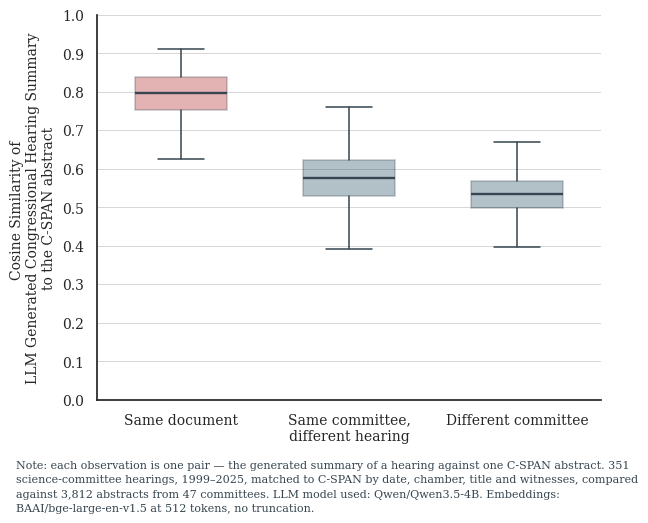

wrote /project2/njia_1089/acroh/projects/llm_method/paper/figures/cosine_similarity_averages.pdf
wrote /project2/njia_1089/acroh/projects/llm_method/paper/figures/cosine_similarity_averages.png


In [5]:
NAVY, RED, CHARCOAL, GRID = "#003049", "#A30006", "#36454F", "#D0D0D0"
sns.set_theme(style="white", font="serif",
              rc={"font.serif": ["DejaVu Serif", "Times New Roman", "serif"],
                  "font.size": 10, "axes.labelsize": 11,
                  "xtick.labelsize": 10, "ytick.labelsize": 10})

fig, ax = plt.subplots(figsize=(6.5, 5.0))
box = ax.boxplot(list(STRATA.values()), widths=0.55, patch_artist=True, showfliers=False,
                 boxprops={"alpha": 0.30, "edgecolor": CHARCOAL, "linewidth": 1.1},
                 medianprops={"color": CHARCOAL, "linewidth": 1.7},
                 whiskerprops={"color": CHARCOAL, "linewidth": 1.1},
                 capprops={"color": CHARCOAL, "linewidth": 1.1})
# The own-hearing comparison is the claim; the two null comparisons share one colour
# so the eye reads them as a pair against it.
for patch, colour in zip(box["boxes"], (RED, NAVY, NAVY)):
    patch.set_facecolor(colour)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(list(STRATA))
ax.set_ylabel("Cosine Similarity of \n"
              "LLM Generated Congressional Hearing Summary\n"
              "to the C-SPAN abstract", fontsize=10)
ax.set_ylim(0.0, 1.0)
ax.set_yticks(np.arange(0.0, 1.01, 0.1))
ax.yaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# The note sits below the x tick labels, left-aligned, wrapped to the figure width
# by matplotlib rather than by hand-placed newlines.
fig.text(
    0.0, -0.01,
    f"Note: each observation is one pair — the generated summary of a hearing against one "
    f"C-SPAN abstract. {len(focal):,} science-committee hearings, "
    f"{focal['year'].min()}\u2013{focal['year'].max()}, matched to C-SPAN by date, chamber, "
    f"title and witnesses, compared against {len(matches):,} abstracts from "
    f"{len(set().union(*matches['committee_ids'].map(set))):,} committees. "
    f"LLM model used: {SUMMARY_MODEL}. "
    f"Embeddings: {ENCODER} at {MAX_LENGTH} tokens, no truncation.",
    ha="left", va="top", wrap=True, fontsize=8, color=CHARCOAL, linespacing=1.5)

fig.savefig(FIGURE, bbox_inches="tight")
fig.savefig(FIGURE.with_suffix(".png"), bbox_inches="tight", dpi=200)
plt.show()
print(f"wrote {FIGURE}")
print(f"wrote {FIGURE.with_suffix('.png')}")